we are going to compare ideal and noisy quantum simulations using Qiskit Aer. The goal is to see how the same quantum circuit can produce different results when realistic gate errors are introduced, and why noise matters when evaluating quantum algorithms.

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.visualization import plot_histogram

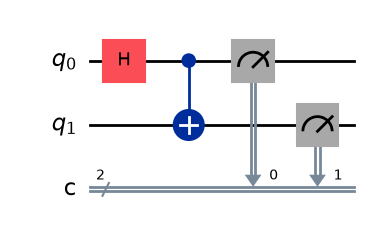

In [3]:
circuit = QuantumCircuit(2, 2)

circuit.h(0)
circuit.cx(0, 1)

circuit.measure([0, 1], [0, 1])

circuit.draw("mpl")

In [4]:
ideal_simulator = AerSimulator()

In [5]:
ideal_result = ideal_simulator.run(
    circuit,
    shots=2000
).result()

ideal_counts = ideal_result.get_counts()

print(ideal_counts)

{'00': 984, '11': 1016}


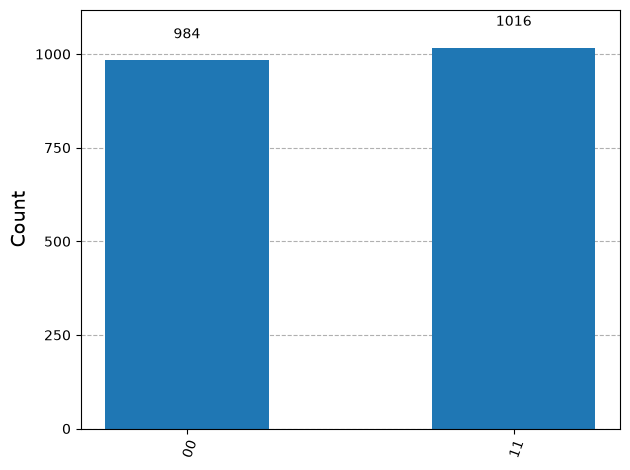

In [6]:
plot_histogram(ideal_counts)

In [7]:
single_qubit_error = depolarizing_error(
    0.02,
    1
)

two_qubit_error = depolarizing_error(
    0.08,
    2
)

In [8]:
noise_model = NoiseModel()

noise_model.add_all_qubit_quantum_error(
    single_qubit_error,
    ["h"]
)

noise_model.add_all_qubit_quantum_error(
    two_qubit_error,
    ["cx"]
)

print(noise_model)

NoiseModel:
  Basis gates: ['cx', 'h', 'id', 'rz', 'sx']
  Instructions with noise: ['cx', 'h']
  All-qubits errors: ['h', 'cx']


In [9]:
noisy_simulator = AerSimulator(
    noise_model=noise_model
)

In [10]:
noisy_result = noisy_simulator.run(
    circuit,
    shots=2000
).result()

noisy_counts = noisy_result.get_counts()

print(noisy_counts)

{'11': 938, '00': 975, '01': 42, '10': 45}


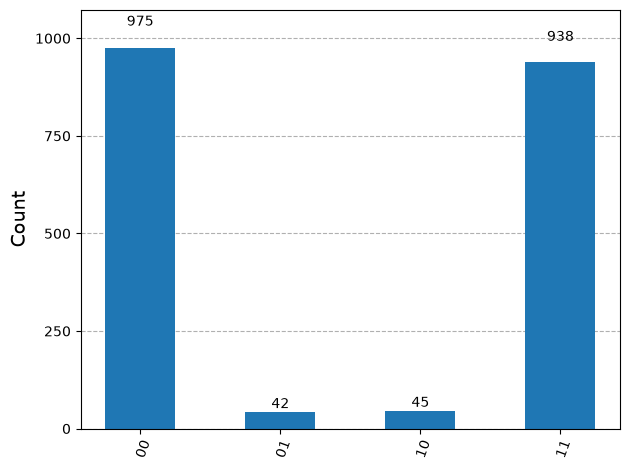

In [11]:
plot_histogram(noisy_counts)

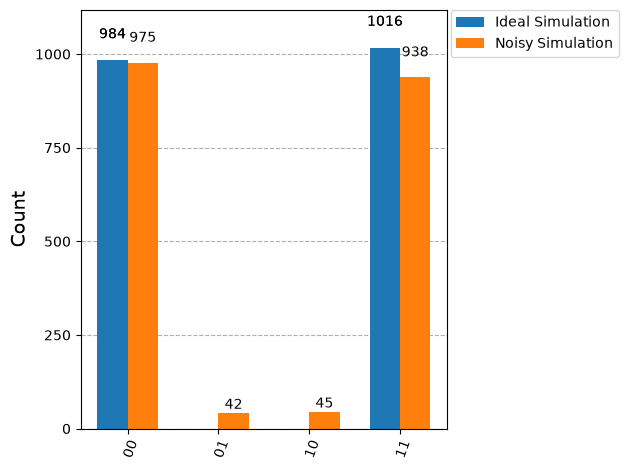

In [12]:
plot_histogram(
    [ideal_counts, noisy_counts],
    legend=[
        "Ideal Simulation",
        "Noisy Simulation"
    ]
)

In [13]:
def correlated_probability(counts):
    total = sum(counts.values())

    correct = (
        counts.get("00", 0)
        + counts.get("11", 0)
    )

    return correct / total

In [14]:
ideal_accuracy = correlated_probability(
    ideal_counts
)

noisy_accuracy = correlated_probability(
    noisy_counts
)

print(
    f"Ideal correlated outcomes: "
    f"{ideal_accuracy:.2%}"
)

print(
    f"Noisy correlated outcomes: "
    f"{noisy_accuracy:.2%}"
)

Ideal correlated outcomes: 100.00%
Noisy correlated outcomes: 95.65%


In [15]:
strong_single_error = depolarizing_error(
    0.08,
    1
)

strong_two_error = depolarizing_error(
    0.20,
    2
)

strong_noise_model = NoiseModel()

strong_noise_model.add_all_qubit_quantum_error(
    strong_single_error,
    ["h"]
)

strong_noise_model.add_all_qubit_quantum_error(
    strong_two_error,
    ["cx"]
)

In [16]:
strong_noisy_simulator = AerSimulator(
    noise_model=strong_noise_model
)

strong_result = strong_noisy_simulator.run(
    circuit,
    shots=2000
).result()

strong_counts = strong_result.get_counts()

print(strong_counts)

{'11': 860, '00': 950, '10': 95, '01': 95}


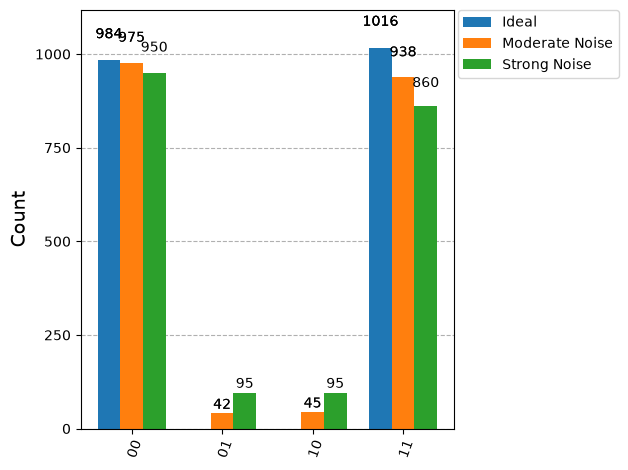

In [17]:
plot_histogram(
    [
        ideal_counts,
        noisy_counts,
        strong_counts
    ],
    legend=[
        "Ideal",
        "Moderate Noise",
        "Strong Noise"
    ]
)

In [18]:
strong_accuracy = correlated_probability(
    strong_counts
)

print(
    f"Ideal accuracy: "
    f"{ideal_accuracy:.2%}"
)

print(
    f"Moderate-noise accuracy: "
    f"{noisy_accuracy:.2%}"
)

print(
    f"Strong-noise accuracy: "
    f"{strong_accuracy:.2%}"
)

Ideal accuracy: 100.00%
Moderate-noise accuracy: 95.65%
Strong-noise accuracy: 90.50%
